# Classificação de Pulsares com Regressão Logística

Modelo para identificar estrelas de nêutrons pulsares reais a partir de medições estatísticas de sinais de rádio, diferenciando pulsares (1) de ruído e outras fontes (0).

## 1. Carregando e explorando os dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_auc_score, ConfusionMatrixDisplay

In [2]:
df = pd.read_csv("pulsar.csv")
df.head()

,Mean of the integrated profile,Standard deviation of the integrated profile,Excess kurtosis of the integrated profile,Skewness of the integrated profile,Mean of the DM-SNR curve,Standard deviation of the DM-SNR curve,Excess kurtosis of the DM-SNR curve,Skewness of the DM-SNR curve,target_class
0,140.562500,55.683782,-0.234571,-0.699648,3.199833,19.110426,7.975532,74.242225,0
1,102.507812,58.882430,0.465318,-0.515088,1.677258,14.860146,10.576487,127.393580,0
2,103.015625,39.341649,0.323328,1.051164,3.121237,21.744669,7.735822,63.171909,0
3,136.750000,57.178449,-0.068415,-0.636238,3.642977,20.959280,6.896499,53.593661,0
4,88.726562,40.672225,0.600866,1.123492,1.178930,11.468720,14.269573,252.567306,0


In [3]:
print("Linhas e colunas:", df.shape)
df.info()

Linhas e colunas: (17898, 9)
<class 'pandas.DataFrame'>
RangeIndex: 17898 entries, 0 to 17897
Data columns (total 9 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Mean of the integrated profile                17898 non-null  float64
 1   Standard deviation of the integrated profile  17898 non-null  float64
 2   Excess kurtosis of the integrated profile     17898 non-null  float64
 3   Skewness of the integrated profile            17898 non-null  float64
 4   Mean of the DM-SNR curve                      17898 non-null  float64
 5   Standard deviation of the DM-SNR curve        17898 non-null  float64
 6   Excess kurtosis of the DM-SNR curve           17898 non-null  float64
 7   Skewness of the DM-SNR curve                  17898 non-null  float64
 8   target_class                                  17898 non-null  int64  
dtypes: float64(8), int64(1)
memory usage: 1.2 MB

In [4]:
df.describe()

,Mean of the integrated profile,Standard deviation of the integrated profile,Excess kurtosis of the integrated profile,Skewness of the integrated profile,Mean of the DM-SNR curve,Standard deviation of the DM-SNR curve,Excess kurtosis of the DM-SNR curve,Skewness of the DM-SNR curve,target_class
count,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000
mean,111.079968,46.549532,0.477857,1.770279,12.614400,26.326515,8.303556,104.857709,0.091574
std,25.652935,6.843189,1.064040,6.167913,29.472897,19.470572,4.506092,106.514540,0.288432
min,5.812500,24.772042,-1.876011,-1.791886,0.213211,7.370432,-3.139270,-1.976976,0.000000
25%,100.929688,42.376018,0.027098,-0.188572,1.923077,14.437332,5.781506,34.960504,0.000000
50%,115.078125,46.947479,0.223240,0.198710,2.801839,18.461316,8.433515,83.064556,0.000000
75%,127.085938,51.023202,0.473325,0.927783,5.464256,28.428104,10.702959,139.309330,0.000000
max,192.617188,98.778911,8.069522,68.101622,223.392141,110.642211,34.539844,1191.000837,1.000000


In [5]:
print("Distribuição da classe (0 = não-pulsar, 1 = pulsar):")
print(df["target_class"].value_counts())
print("Percentual de pulsares:", round(df["target_class"].mean() * 100, 2), "%")
print("Valores nulos:", df.isnull().sum().sum())

Distribuição da classe (0 = não-pulsar, 1 = pulsar):
target_class
0    16259
1     1639
Name: count, dtype: int64
Percentual de pulsares: 9.16 %
Valores nulos: 0


A base é desbalanceada: apenas cerca de 9% das observações são pulsares reais. Por isso, além da acurácia, olhamos sensibilidade e especificidade.

### Distribuição das classes

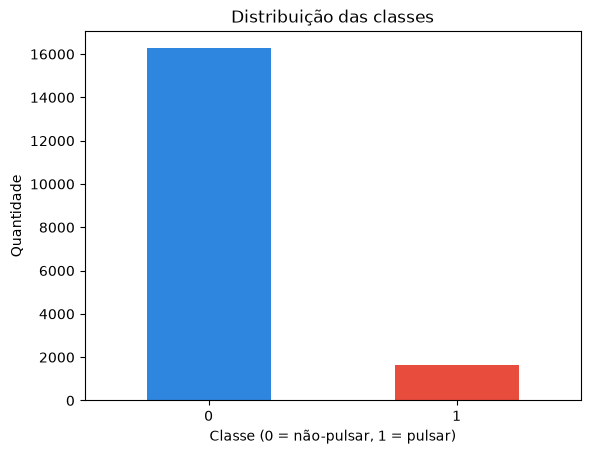

In [6]:
df["target_class"].value_counts().plot(kind="bar", color=["#2E86DE", "#E74C3C"])
plt.title("Distribuição das classes")
plt.xlabel("Classe (0 = não-pulsar, 1 = pulsar)")
plt.ylabel("Quantidade")
plt.xticks(rotation=0)
plt.show()

## 2. Preparação e divisão dos dados

In [7]:
X = df.drop(columns=["target_class"])
y = df["target_class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Treino:", X_train.shape[0], "| Teste:", X_test.shape[0])

Treino: 14318 | Teste: 3580


### Padronização dos atributos

A regressão logística funciona melhor com os atributos na mesma escala, então padronizamos (média 0, desvio 1).

In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 3. Treinando a regressão logística

In [9]:
modelo = LogisticRegression(max_iter=1000)
modelo.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

## 4. Avaliação do modelo

In [10]:
y_pred = modelo.predict(X_test_scaled)
print("Acurácia:", round(accuracy_score(y_test, y_pred), 4))
print("AUC:", round(roc_auc_score(y_test, modelo.predict_proba(X_test_scaled)[:, 1]), 4))

Acurácia: 0.9796
AUC: 0.971


In [11]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

sensibilidade = tp / (tp + fn)
especificidade = tn / (tn + fp)

print("Sensibilidade (detecção de pulsares):", round(sensibilidade, 4))
print("Especificidade (evitar falsos positivos):", round(especificidade, 4))

Sensibilidade (detecção de pulsares): 0.8262
Especificidade (evitar falsos positivos): 0.9951


In [12]:
print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           0      0.983     0.995     0.989      3252
           1      0.944     0.826     0.881       328

    accuracy                          0.980      3580
   macro avg      0.963     0.911     0.935      3580
weighted avg      0.979     0.980     0.979      3580



### Matriz de confusão

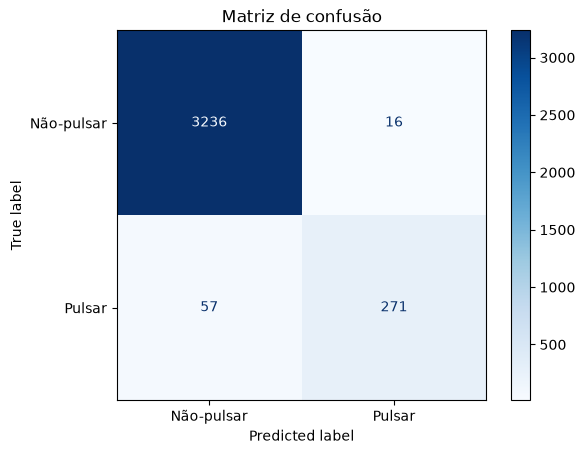

In [13]:
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Não-pulsar", "Pulsar"]).plot(cmap="Blues")
plt.title("Matriz de confusão")
plt.show()

## Conclusões

- A base é grande (quase 18 mil observações) e desbalanceada: apenas cerca de 9% são pulsares reais.
- Após padronizar os atributos, a regressão logística alcançou acurácia de cerca de 98% e AUC de 0,97, indicando ótima capacidade de separar as classes.
- A especificidade (~99,5%) é altíssima: quase não gera falsos alarmes. A sensibilidade (~83%) é boa, mas mostra que o modelo deixa passar cerca de 17% dos pulsares — algo esperado em base desbalanceada.
- No geral, a regressão logística se mostrou eficiente e confiável para este problema, especialmente pela simplicidade. Para aumentar a sensibilidade, seria possível ajustar o limiar de decisão ou tratar o desbalanceamento.